# ПЗ-7. Дифференцирование через комплексный шаг

> 🎮 Лекция 6 закончилась $U$-кривой: у разностей
> есть оптимальный шаг и потолок точности $\sim\sqrt{\varepsilon}$.
> Сегодня мы "шагнём вверх" - в мнимое направление - и посмотрим,
> что станет с кривой. А заодно будем **подозревать** функции
> в неаналитичности и построим детектор.

| уровень | метка | что это значит |
|---|---|---|
| 🟢 | прогрев | детский сад |
| 🟠 | продвинутая | базовый минимум |
| ★ | звёздочка | альфа |
| ★★ | двойная звёздочка | сигма |

**Как работать.** Постановки — в md-блоках, решаете — в ячейках
`✍️ ДЕЛАЙТЕ`. После каждой задачи стоит ячейка `✅ Самопроверка`:
она исполняется без ошибок только при верном решении. Идите сверху
вниз.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 110
print('numpy', np.__version__)

numpy 2.5.4


## 📋 Шпаргалка

$f$ вещественна на оси и **аналитична**. Ряд Тейлора в точке $x$
с чисто мнимым приращением:
$f(x+ih) = \sum_k \frac{(ih)^k}{k!}\,f^{(k)}(x)$:
мнимую часть собирают **нечётные** степени, вещественную — чётные.

| формула | главный остаток | комментарий |
|---|---|---|
| комплексный шаг: $f' \approx S(h) = \dfrac{\mathrm{Im}\, f(x+ih)}{h}$ | $-\tfrac{h^2}{6}f''' + \tfrac{h^4}{120}f^{(5)}+\dots$ | **нет вычитания** → шум $\delta/h$ не растёт, «плоская линия» |
| центральная (для сравнения) | $-\tfrac{h^2}{6}f'''$ | та же $O(h^2)$, но $+\,\delta/h$ от округления → дно $\sim\sqrt{\varepsilon}$ |
| вторая через Re: $f'' \approx \dfrac{2\,(f(x) - \mathrm{Re}\,f(x+ih))}{h^2}$ | $-\tfrac{h^2}{12}f^{(4)}$ | вычитание **вернулось** → снова $U$-кривая |
| Ричардсон: $f' \approx \dfrac{4S(h) - S(2h)}{3}$ | $-\tfrac{h^4}{30}f^{(5)}$ | порядок 4|

**Три ограничения метода.** (1) функция обязана быть аналитичной
(сходящийся ряд Тейлора в комплексной окрестности); (2) код, ветвящийся
по знаку вещественной части (`abs`, `max`, `if x>0`), уводит комплексную
пробу не в ту ветку; (3) все операции внутри обязаны понимать
`complex` (в `numpy` — обычно да).

подопытный: f = exp(x), x0 = 0.5, точная f' = 1.648721270700128


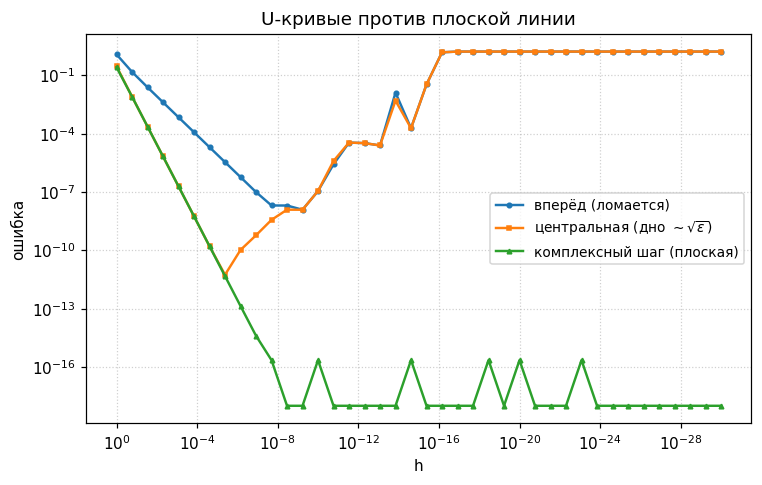

In [2]:
# Обзор матча: U-кривые разностей против «плоской линии» комплексного шага. Смотрим
f = lambda x: np.exp(x)
x0, exact = 0.5, float(np.exp(0.5))
hs = np.logspace(0.0, -30.0, 40)
err_fw, err_ce, err_cs = [], [], []
for h in hs:
    err_fw.append(abs((f(x0 + h) - f(x0)) / h - exact))
    err_ce.append(abs((f(x0 + h) - f(x0 - h)) / (2 * h) - exact))
    err_cs.append(abs(np.imag(f(x0 + 1j * h)) / h - exact))
floor = 1e-18
err_fw = np.maximum(err_fw, floor)
err_ce = np.maximum(err_ce, floor)
err_cs = np.maximum(err_cs, floor)
print(f"подопытный: f = exp(x), x0 = {x0}, точная f' = {exact:.15f}")

fig, ax = plt.subplots(figsize=(7.8, 4.6))
ax.loglog(hs, err_fw, 'o-', ms=3, lw=1.6, label='вперёд (ломается)')
ax.loglog(hs, err_ce, 's-', ms=3, lw=1.6, label='центральная (дно $\\sim\\sqrt{\\varepsilon}$)')
ax.loglog(hs, err_cs, '^-', ms=3, lw=1.6, label='комплексный шаг (плоская)')
ax.invert_xaxis()
ax.set_xlabel('h'); ax.set_ylabel('ошибка')
ax.set_title('U-кривые против плоской линии')
ax.grid(True, which='both', linestyle=':', alpha=0.6)
ax.legend(fontsize=9)
plt.show()

---
## 🟢 Задача 1. Комплексный шаг на три функции

Внедрим формулу «комплексный шаг» и посмотрим на её поведение при давлении шага. Подопытные:

$$f_1(x) = e^x \ (x_0 = 0.5), \qquad f_2(x) = \sin x \ (x_0 = 1.0),
\qquad f_3(x) = e^{x}\sin x \ (x_0 = 0.8).$$

Будем уменьшать шаг: $h = 10^{-2}, 10^{-4}, 10^{-6}, 10^{-8}, 10^{-20}$.

**Что сделать:**

- **(а)** Реализовать `cs_diff(f, x0, h)` по шпаргалке.
- **(б)** Таблица ошибок $|S(h) - f'(x_0)|$: ошибка при $h/100$
  падает **в $10^4$** раз (каким порядком это обещано?).
- **(в)** Собрать `E_MAX` - максимум ошибки по $h \in \{10^{-8},
  10^{-20}\}$ (возбмите какой-то шаг любой адекватный, чтобы норм нарисовать) для всех трёх подопытных. Сравните с минимум функции ошибки от шага центральной
  разности из Лекции 6.

> 💡 Функции из `numpy` понимают `complex` «из коробки» 

In [3]:
# Каркас задачи 1: подопытные и точные производные
F1, DF1_EX, X01 = lambda x: np.exp(x), lambda t: float(np.exp(t)), 0.5
F2, DF2_EX, X02 = lambda x: np.sin(x), lambda t: float(np.cos(t)), 1.0
F3, DF3_EX, X03A = (lambda x: np.exp(x) * np.sin(x),
                    lambda t: float(np.exp(t) * (np.sin(t) + np.cos(t))), 0.8)
HS1 = [1e-2, 1e-4, 1e-6, 1e-8, 1e-20]
for name, x0 in [("f1 = exp", X01), ("f2 = sin", X02), ("f3 = exp*sin", X03A)]:
    print(name, "| x0 =", x0)
print("сетка шагов:", HS1)
print("спросите себя: при h/100 ошибка падает ~10^4 раз у какой формулы?")

f1 = exp | x0 = 0.5
f2 = sin | x0 = 1.0
f3 = exp*sin | x0 = 0.8
сетка шагов: [0.01, 0.0001, 1e-06, 1e-08, 1e-20]
спросите себя: при h/100 ошибка падает ~10^4 раз у какой формулы?


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 1
# TODO (а): def cs_diff(f, x0, h): ...
# TODO (б): таблица ошибок |cs_diff - точная| для всех трёх подопытных и всех HS1
# TODO (в): E_MAX = максимум ошибки по h из {1e-8, 1e-20} и всем трём функциям


In [ ]:
# ✅ Самопроверка задачи 1
import numpy as np
assert E_MAX < 1e-13, f"машинное дно сложного шага превышено: {E_MAX:.2e} — проверьте формулу"
print(f"✅ Задача 1 ок: max err по h в {{1e-8, 1e-20}}: {E_MAX:.2e} — плоская линия на машинном дне")

---
## 🟠 Задача 2. Смерть разности

Эксперимент: возьмём шаг $h = 10^{-17}$. Относительное смещение
$h/x_0 = 2\cdot10^{-17}$ вдвое меньше машинного эпсилон
$\varepsilon_{\text{маш}} \approx 2.2\cdot10^{-16}$, поэтому в float
$e^{x_0 \pm h}$ округляется **точно** в то же число, что $e^{x_0}$.

**Что сделать:**

- **(а)** Для $f = e^x$ в $x_0 = 0.5$ при $h = 10^{-17}$ вычислить
  **значения** формул «вперёд» и «центральная» - `EST17_FW`,
  `EST17_CE` - и **ошибку** комплексного шага `ERR17_CS`.
- **(б)** Убедиться и объяснить: почему первые две
  «умерли» (обнулились), а комплексный шаг жив и точен до машинного
  эпсилон. Почему $h$ всё ещё «жив» внутри $f(x_0 + ih)$?

In [4]:
# Каркас задачи 2: казнь разностей при сверхмалом шаге
f_death = lambda x: np.exp(x)
X0D, H_DEATH = 0.5, 1e-17
EXACTD = float(np.exp(X0D))
EPSM = float(np.finfo(float).eps)
HS_D = [1e-5, 1e-12, 1e-17]
print(f"f = exp, x0 = {X0D}, точная f' = {EXACTD:.15f}")
print(f"eps_маш = {EPSM:.3e}; относительный шаг h/x0 = {H_DEATH / X0D:.1e}")
print("предсказание: e^(x0 ± h) округлится в e^x0 впритык — числитель станет нулём")

f = exp, x0 = 0.5, точная f' = 1.648721270700128
eps_маш = 2.220e-16; относительный шаг h/x0 = 2.0e-17
предсказание: e^(x0 ± h) округлится в e^x0 впритык — числитель станет нулём


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 2
# TODO (а): EST17_FW, EST17_CE — значения формул вперёд/центральная при h = 1e-17;
#            ERR17_CS — ошибка комплексного шага при том же h
# TODO (б): объяснение печатными строками (почему умерли две и жива третья)
# TODO (в): таблица оценок/ошибок на HS_D


In [ ]:
# ✅ Самопроверка задачи 2
import numpy as np
assert EST17_FW == 0.0, f"вперёд обязана умереть в ноль: {EST17_FW!r}"
assert EST17_CE == 0.0, f"центральная тоже обязана умереть: {EST17_CE!r}"
assert ERR17_CS < 2e-15, f"комплексный шаг обязан быть жив: {ERR17_CS!r}"
print(f"✅ Задача 2 ок: fw = ce = 0 (смерть), cs err = {ERR17_CS:.2e} (машинное дно)")

---
## 🟠 Задача 3. Кто здесь аналитичен: таблица подозреваемых

Получили досье на шесть функций. Три - честные аналитические ровные ребята, три -
грязные вруны:

| i | функция | $x_0$ | точная $f'$ |
|---|---|---|---|
| 0 | $e^x$ | $0.5$ | $e^{x_0}$ |
| 1 | $\sin x$ | $1.0$ | $\cos x_0$ |
| 2 | $\sqrt{x}$ | $1.0$ | $0.5$ |
| 3 | $\|x\|$ | $0$ | не существует |
| 4 | `max(x, 0)` | $0$ | правая $=1$, средней нет |
| 5 | $x\,\|x\|$ | $0$ | $0$ (гладкая, но $\ne$ аналитическое продолжение) |

**Что сделать:**

- **(а)** Для каждой функции вычислить: два значения комплексного
  шага ($h = 10^{-6}$ и $10^{-7}$) - в списки `CS1`, `CS2`; и
  центральную разность при $h = 10^{-5}$ - в `CENTR`.
- **(б)** Для аналитических (i = 0, 1, 2) напечатать ошибку
  комплексного шага относительно точной - и убедиться, что она
  машинная.
- **(в)** Собрать `FLAGS` - булев список подозрительных актвиностей.
  Критерий диагностики: комплексный шаг **стабилен**
  ($|CS1_i - CS2_i|$ мал по сравнению с масштабом) и **расходится
  с центральной разностью**.
- **(г)** Кто в итоге спалился?

> 💡 `np.abs` на комплексной плоскости возвращает **вещественный** float —
> тогда `np.imag` читает ноль. Подумайте, что именно это ломает.

In [5]:
# Каркас задачи 3: досье подозреваемых
F_EXP = np.exp
F_SIN = np.sin
F_SQRT = np.sqrt
F_ABS = np.abs
F_MAXB = lambda z: z * (np.real(z) > 0.0)
F_XAX = lambda z: z * np.abs(z)
PROBES = [("exp", F_EXP, 0.5), ("sin", F_SIN, 1.0), ("sqrt", F_SQRT, 1.0),
          ("abs", F_ABS, 0.0), ("max(x,0)", F_MAXB, 0.0),
          ("x*|x|", F_XAX, 0.0)]
H1, H2, HC = 1e-6, 1e-7, 1e-5
print('досье:')
for i, (name, fnc, x0) in enumerate(PROBES):
    print(f'  [{i}] {name:<8} x0 = {x0}')
print("cs при h = 1e-6 и 1e-7; центральная при h = 1e-5")
print("(для аналитических точные производные: e^x -> exp(x0), sin -> cos(x0), sqrt -> 0.5)")

досье:
  [0] exp      x0 = 0.5
  [1] sin      x0 = 1.0
  [2] sqrt     x0 = 1.0
  [3] abs      x0 = 0.0
  [4] max(x,0) x0 = 0.0
  [5] x*|x|    x0 = 0.0
cs при h = 1e-6 и 1e-7; центральная при h = 1e-5
(для аналитических точные производные: e^x -> exp(x0), sin -> cos(x0), sqrt -> 0.5)


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 3
# TODO (а): списки CS1, CS2, CENTR (по одному значению на каждого подозреваемого)
# TODO (б): ошибки cs относительно точных у аналитических (печать)
# TODO (в): FLAGS — булевы флаги «похоже на поломку» (стабильность + расхождение)
# TODO (г): печатный разбор каждого дела


In [ ]:
# ✅ Самопроверка задачи 3
import numpy as np
EX3 = [float(np.exp(0.5)), float(np.cos(1.0)), 0.5]
for i in (0, 1, 2):
    assert abs(CS1[i] - EX3[i]) < 1e-12, (
        f"у аналитической №{i} cs должен быть точен: {CS1[i]!r}")
assert CS1[3] < 1e-25, "abs: cs обязан дать ровно 0"
assert FLAGS[3] == False, "abs: cs 0 и central 0 согласованы — флага быть не должно"
assert FLAGS[4] == True, "у max(x,0) детектор обязан сработать (cs 0 против central 1/2)"
assert abs(CENTR[4] - 0.5) < 1e-12, f"central у max(x,0) = 0.5: {CENTR[4]!r}"
assert CS1[5] < 2.5e-6, f"x|x|: cs обязан дать ~h = 1e-6 (вышло {CS1[5]!r})"
assert FLAGS == [False, False, False, False, True, False], f"FLAGS = {FLAGS!r}"
print("✅ Задача 3 ок: аналитические точны, max-ветка поймана, "
      "abs — согласованный мусор, x*|x| — нестабильно верный)")

---
## 🟠 Задача 4. $f''$ через Re: $U$-кривая возвращается

Из вещественной части ряда: $f'' \approx 2\,(f(x) - \mathrm{Re}\,f(x+ih))/h^2$
— вычитание вернулось, значит вернулся шум $1/h^2$ и $U$-кривая.
Подопытный: $f = e^x$ в $x_0 = 0.5$; теория обещает

$$h_* = \Bigl(\dfrac{24\,\varepsilon_{\text{маш}}\,|f(x_0)|}{|f^{(4)}(x_0)|}\Bigr)^{1/4}.$$

**Что сделать:**

- **(а)** По сетке `HS2` построить ошибку формулы через Re
  (`ERRA[i]`) и для сравнения - обычной второй разности
  (метод $O(h^2)$ из Л6). Нарисовать обе $\log$-$\log$ кривые вертикальный пунктир `H_STAR2`.
- **(б)** Найти `H_FOUND2` (шаг минимума `ERRA`) и `ERR_MIN2`.
- **(в)** Печатный итог: действительно ли минимум $f''$ поднимается на
  много-много порядков над машинным эпсилон (в отличие от первой
  производной из задачи 1)? Сравните с минимумом из Лекции 6.


In [6]:
# Каркас задачи 4: сетка шагов и теоретический оптимум
X04, F4 = 0.5, np.exp
DF2_EX = float(np.exp(X04))          # f''(x0)
F4DER4 = float(np.exp(X04))          # f''''(x0) — у exp всё та же экспонента
EPS_MACH = float(np.finfo(float).eps)
HS2 = np.logspace(-1.0, -6.0, 50)
H_STAR2 = (24.0 * EPS_MACH * abs(F4(X04)) / F4DER4) ** 0.25
print(f"f = exp, x0 = {X04}, f'' = {DF2_EX:.12f}")
print(f"eps_маш = {EPS_MACH:.3e},  теория: h* = (24*eps*|f|/f'^'''')^(1/4) = {H_STAR2:.3e}")
print("сетка HS2: от 1e-1 до 1e-6, 50 точек")

f = exp, x0 = 0.5, f'' = 1.648721270700
eps_маш = 2.220e-16,  теория: h* = (24*eps*|f|/f'^'''')^(1/4) = 2.702e-04
сетка HS2: от 1e-1 до 1e-6, 50 точек


In [7]:
# ✍️ ДЕЛАЙТЕ — Задача 4
# TODO (а): ERRA[i] — ошибка формулы через Re на каждом HS2[i]
#           + сравнение с обычной второй разностью; loglog-график; пунктир H_STAR2
# TODO (б): H_FOUND2 = HS2[argmin(ERRA)], ERR_MIN2 = min(ERRA), печать
# TODO (в): печатный итог про дно


In [ ]:
# ✅ Самопроверка задачи 4
import numpy as np
ratio4 = H_FOUND2 / H_STAR2
assert 0.2 < ratio4 < 5.0, f"оптимум далеко от теории: {ratio4:.2f} × h*"
assert 1e-11 < ERR_MIN2 < 1e-7, (
    f"дно второй производной обязано быть много выше машинного эпсилон, но не 1e-7: {ERR_MIN2:.2e}")
print(f"✅ Задача 4 ок: h_found = {H_FOUND2:.3e} ({ratio4:.2f}×h*), "
      f"дно f'' ≈ {ERR_MIN2:.2e} — U-кривая вернулась")

---
## ★ Задача 5. Ричардсон по комплексному шагу: порядок 4 без вычитания

Оценка $S(h)$ получается через  ряд

$$S(h) = f'(x_0) - \tfrac{h^2}{6}f''' + \tfrac{h^4}{120}f^{(5)} - \dots$$

Ричардсон объединяет **две оценки** (шаги $h$ и $2h$), чтобы убить
член $h^2$, но структура «нет вычитания» при этом не портится:

$$R(h) = \dfrac{4S(h) - S(2h)}{3} = f'(x_0) - \tfrac{h^4}{30}f^{(5)} - \dots$$

Подопытный: $f = e^x$, $x_0 = 0.5$, шаги $h = 0.1,\ 0.05,\ 0.02$
и контрольный $\ h = 10^{-8}$ (там хотим увидеть дно).

**Что сделать:**

- **(а)** Построить `ERR_S` (ошибки $S(h)$) и `ERR_R` (ошибки $R(h)$)
  для трёх шагов; 
- **(б)** Убедиться: у $S$ - падение в 4 раза, у $R$ - в 16
  (порядок 2 против порядка 4).
- **(в)** Печатный вывод: насколько $R$ точнее $S$ на $h = 0.05$,
  и что происходит в минимуме (почему Ричардсон не портит «плоскую
  линию»?).


In [8]:
# Каркас задачи 5: сетка шагов Ричардсона
X0R, FR = 0.5, np.exp
DF_EXR = float(np.exp(X0R))          # f'(x0)
HS_R = [0.1, 0.05, 0.02]
H_FLAT = 1e-8
print(f"f = exp, x0 = {X0R}, точная f' = {DF_EXR:.15f}")
print("S(h) = Im f(x+ih)/h;   R(h) = (4*S(h) - S(2*h)) / 3")
print("шаги:", HS_R, "| контрольная глубина h =", H_FLAT)
print("теория: err(S) ~ h^2/6 * f''',  err(R) ~ h^4/30 * f^(5)")

f = exp, x0 = 0.5, точная f' = 1.648721270700128
S(h) = Im f(x+ih)/h;   R(h) = (4*S(h) - S(2*h)) / 3
шаги: [0.1, 0.05, 0.02] | контрольная глубина h = 1e-08
теория: err(S) ~ h^2/6 * f''',  err(R) ~ h^4/30 * f^(5)


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 5 (звёздочка)
# TODO (а): ERR_S — список ошибок S(h) на HS_R; ERR_R — то же для R(h)
# TODO (б): таблица с отношениями ошибок при h/2; ERR_RF = err R(h=1e-8)
# TODO (в): вывод печатными строками


In [ ]:
# ✅ Самопроверка задачи 5
import numpy as np
ratio_S = ERR_S[0] / ERR_S[1]
ratio_R = ERR_R[0] / ERR_R[1]
gain = ERR_S[1] / ERR_R[1]
assert 3.6 < ratio_S < 4.4, f"S: порядок 2 — падение в 4 (вышло {ratio_S:.2f})"
assert 10.0 < ratio_R < 22.0, f"R: порядок 4 — падение в 16 (вышло {ratio_R:.2f})"
assert ERR_R[2] < 2e-8, f"R(0.02) у exp обязана быть ~8.8e-9: {ERR_R[2]:.2e}"
assert ERR_RF < 1e-12, f"дно Ричардсона обязано быть машинным: {ERR_RF:.2e}"
assert gain > 300, f"R на h=0.05 обязан быть на порядки точнее S: {gain:.0f}×"
print(f"✅ Задача 5 ок: падения {ratio_S:.1f}x и {ratio_R:.1f}x; "
      f"усиление {gain:.0f}x; дно R = {ERR_RF:.2e}")

---
## ★★ Задача 6. Финальный вызов: детектор аналитичности

Свяжем всё в один прибор. Для произвольной функции $g$ и точки $x_0$
соберём показания: `s1` и `s2` — комплексный шаг при $h$ и $h/10$,
`c` — центральная разность при $h_c$. Вердикт - флаг:

$$\text{flag} = \underbrace{(\ |s_1 - s_2|\ \text{мала}\ )}_{\text{cs стабилен}}
\ \wedge\ \underbrace{(\ |s_1 - c|\ \text{велика}\ )}_{\text{cs против central}}$$

Набор для проверки прибора:

| i | функция | $x_0$ | ожидание поломки |
|---|---|---|---|
| 0 | $e^x \sin x$ | $0.7$ | не поломается, так как аналитична |
| 1 | `x * (Re x > 0)` | $0$ | ступенька в нуле - **поломка** |
| 2 | $\|x\|$ | $0$ | производной нет, но оба метода дают $0$  |
| 3 | $x\,\|x\|$ | $0$ | cs гуляет вместе с $h$ - нестабильность |

**Что сделать:**

- **(а)** Реализовать `analyzer(g, x0, h0=1e-6, h1=1e-7, hc=1e-5)`
  → `(s1, s2, c, flag)`;
- **(б)** Прогнать по набору фукнций: кого детектор ловит, кого законно пропускает и почему.
- **(в)** почему $\|x\|$ -
  слепая зона детектора, и что поможет это испарвить (подсказка: ПЗ-8,
  `gradcheck`).


In [10]:
# Каркас задачи 6: подопытные для детектора
G_ANALYTIC = lambda z: np.exp(z) * np.sin(z)     # аналитическая
G_STEP = lambda z: z * (np.real(z) > 0.0)        # ветвление по знаку Re
G_ABS = np.abs                                   # согласованный мусор
G_XAX = lambda z: z * np.abs(z)                  # нестабильный cs
DETECT_PROBES = [("exp*sin", G_ANALYTIC, 0.7), ("step(x)", G_STEP, 0.0),
                 ("abs", G_ABS, 0.0), ("x*|x|", G_XAX, 0.0)]
print("Нормативы прибора: h0 = 1e-6 (cs), h1 = 1e-7 (cs), hc = 1e-5 (central)")
print("flag = (cs стабилен) И (cs расходится с central); масштаб — max(1, |s1|)")
for i, (name, g, x0) in enumerate(DETECT_PROBES):
    print(f'  [{i}] {name:<8} x0 = {x0}')

Нормативы прибора: h0 = 1e-6 (cs), h1 = 1e-7 (cs), hc = 1e-5 (central)
flag = (cs стабилен) И (cs расходится с central); масштаб — max(1, |s1|)
  [0] exp*sin  x0 = 0.7
  [1] step(x)  x0 = 0.0
  [2] abs      x0 = 0.0
  [3] x*|x|    x0 = 0.0


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 6 (финал!)
# TODO (а): def analyzer(g, x0, h0=1e-6, h1=1e-7, hc=1e-5): -> (s1, s2, c, flag)
# TODO (б): таблица показаний по DETECT_PROBES + печатные вердикты
# TODO (в): рефлексия про «слепую зону» и gradcheck


In [ ]:
# ✅ Самопроверка задачи 6
import numpy as np
SHOWS = [analyzer(g, x0) for _, g, x0 in DETECT_PROBES]
FLAGS2 = [s[3] for s in SHOWS]
assert FLAGS2 == [False, True, False, False], f"FLAGS2 = {FLAGS2!r}"
s_step, c_step = SHOWS[1][0], SHOWS[1][2]
assert s_step < 1e-20, f"степень на ветке: cs должен дать 0 (вышло {s_step!r})"
assert abs(c_step - 0.5) < 1e-12, f"central на ступеньке обязан дать 0.5: {c_step!r}"
assert abs(SHOWS[2][0]) < 1e-25 and abs(SHOWS[2][2]) < 1e-25, (
    "abs: оба метода обязаны дать ровно 0 — согласованный мусор")
assert abs(SHOWS[3][0]) < 2.5e-6, f"x|x|: cs ~ h = 1e-6 (вышло {SHOWS[3][0]!r})"
assert abs(SHOWS[0][0] - float(np.exp(0.7) * (np.sin(0.7) + np.cos(0.7)))) < 1e-12, (
    "аналитическая обязана быть точной до машинного дна")
print("✅ Задача 6 ок: детектор ловит ступеньку, молчит на аналитической,")
print("   пропускает согласованный мусор (abs) и отказывается верить "
      "нестабильному cs (x*|x|) — gradcheck из ПЗ-8 закроет остальное)")